# 稠密连接网络（DenseNet）

ResNet极大地改变了如何参数化深层网络中函数的观点。
*稠密连接网络*（DenseNet） :cite:`Huang.Liu.Van-Der-Maaten.ea.2017`在某种程度上是ResNet的逻辑扩展。让我们先从数学上了解一下。

## 从ResNet到DenseNet

回想一下任意函数的泰勒展开式（Taylor expansion），它把这个函数分解成越来越高阶的项。在$x$接近0时，

$$f(x) = f(0) + f'(0) x + \frac{f''(0)}{2!}  x^2 + \frac{f'''(0)}{3!}  x^3 + \ldots.$$

同样，ResNet将函数展开为

$$f(\mathbf{x}) = \mathbf{x} + g(\mathbf{x}).$$

也就是说，ResNet将$f$分解为两部分：一个简单的线性项和一个复杂的非线性项。
那么再向前拓展一步，如果我们想将$f$拓展成超过两部分的信息呢？
一种方案便是DenseNet。

![ResNet（左）与 DenseNet（右）在跨层连接上的主要区别：使用相加和使用连结。](../img/densenet-block.svg)
:label:`fig_densenet_block`

如 :numref:`fig_densenet_block`所示，ResNet和DenseNet的关键区别在于，DenseNet输出是*连接*（用图中的$[,]$表示）而不是如ResNet的简单相加。
因此，在应用越来越复杂的函数序列后，我们执行从$\mathbf{x}$到其展开式的映射：

$$\mathbf{x} \to \left[
\mathbf{x},
f_1(\mathbf{x}),
f_2([\mathbf{x}, f_1(\mathbf{x})]), f_3([\mathbf{x}, f_1(\mathbf{x}), f_2([\mathbf{x}, f_1(\mathbf{x})])]), \ldots\right].$$

最后，将这些展开式结合到多层感知机中，再次减少特征的数量。
实现起来非常简单：我们不需要添加术语，而是将它们连接起来。
DenseNet这个名字由变量之间的“稠密连接”而得来，最后一层与之前的所有层紧密相连。
稠密连接如 :numref:`fig_densenet`所示。

![稠密连接。](../img/densenet.svg)
:label:`fig_densenet`

稠密网络主要由2部分构成：*稠密块*（dense block）和*过渡层*（transition layer）。
前者定义如何连接输入和输出，而后者则控制通道数量，使其不会太复杂。

## (**稠密块体**)

DenseNet使用了ResNet改良版的“批量规范化、激活和卷积”架构（参见 :numref:`sec_resnet`中的练习）。
我们首先实现一下这个架构。


In [1]:
import torch
from torch import nn
from d2l import torch as d2l


def conv_block(input_channels, num_channels):
    """
    DenseNet 的基本卷积块（也叫 "H 函数" / bottleneck 的组成部分之一）。

    顺序：BatchNorm → ReLU → Conv3×3
    注意：与 ResNet 的 "Conv → BN → ReLU" 顺序不同！

    参数：
        input_channels : 输入通道数
        num_channels   : 输出通道数（本块新产生的特征通道数）
    返回：
        nn.Sequential：BN → ReLU → Conv2d(3×3, p=1)
    """
    return nn.Sequential(
        nn.BatchNorm2d(input_channels),                      # ① 批归一化
        nn.ReLU(),                                           # ② 激活
        nn.Conv2d(input_channels, num_channels,              # ③ 3×3 卷积，padding=1 保持尺寸
                  kernel_size=3, padding=1)
    )

一个*稠密块*由多个卷积块组成，每个卷积块使用相同数量的输出通道。
然而，在前向传播中，我们将每个卷积块的输入和输出在通道维上连结。


In [3]:
class DenseBlock(nn.Module):
    def __init__(self, num_convs, input_channels, num_channels):
        """
        稠密块：由 num_convs 个 conv_block 串联而成。

        参数：
            num_convs      : 块内 conv_block 的个数（层数）
            input_channels : 该块的输入通道数
            num_channels   : 每个 conv_block 新产生的通道数（即增长率 growth rate g）
        """
        super(DenseBlock, self).__init__()

        layer = []
        for i in range(num_convs):
            # 关键：第 i 个 conv_block 的输入通道数 =
            #       原始输入通道 + 前面 i 个块各新增的 num_channels
            #   i=0: input_channels
            #   i=1: input_channels + num_channels
            #   i=2: input_channels + 2*num_channels
            #   ...
            layer.append(conv_block(
                num_channels * i + input_channels, num_channels))
        self.net = nn.Sequential(*layer)

    def forward(self, X):
        for blk in self.net:
            Y = blk(X)                  # 当前 conv_block 输出：num_channels 通道，尺寸不变
            # 核心：在通道维拼接 输入 X 和 输出 Y
            X = torch.cat((X, Y), dim=1)  # 总通道数 += num_channels
        return X

在下面的例子中，我们[**定义一个**]有2个输出通道数为10的(**`DenseBlock`**)。
使用通道数为3的输入时，我们会得到通道数为$3+2\times 10=23$的输出。
卷积块的通道数控制了输出通道数相对于输入通道数的增长，因此也被称为*增长率*（growth rate）。


In [4]:
# 创建稠密块：2 个 conv_block，输入 3 通道，每块新增 10 通道（增长率 g=10）
blk = DenseBlock(2, 3, 10)

# 随机输入：(batch=4, C=3, H=8, W=8)
X = torch.randn(4, 3, 8, 8)

# 前向传播
Y = blk(X)

# 查看输出形状
Y.shape

torch.Size([4, 23, 8, 8])

## [**过渡层**]

由于每个稠密块都会带来通道数的增加，使用过多则会过于复杂化模型。
而过渡层可以用来控制模型复杂度。
它通过$1\times 1$卷积层来减小通道数，并使用步幅为2的平均汇聚层减半高和宽，从而进一步降低模型复杂度。


In [5]:
def transition_block(input_channels, num_channels):
    """
    DenseNet 的过渡层：连接两个 DenseBlock，负责"降维 + 下采样"。

    作用：
        ① 用 1×1 卷积把通道数从 input_channels 压缩到 num_channels
        ② 用 2×2 平均池化把空间尺寸减半
    这样可控制 DenseBlock 拼接导致的通道爆炸，并逐步降低分辨率。

    参数：
        input_channels : 输入通道数（上一个 DenseBlock 的输出通道）
        num_channels   : 输出通道数（通常取 input_channels 的一半）
    """
    return nn.Sequential(
        nn.BatchNorm2d(input_channels),                          # ① 批归一化
        nn.ReLU(),                                               # ② 激活
        nn.Conv2d(input_channels, num_channels, kernel_size=1),  # ③ 1×1 卷积：通道降维，尺寸不变
        nn.AvgPool2d(kernel_size=2, stride=2)                    # ④ 2×2 平均池化：尺寸减半
    )

对上一个例子中稠密块的输出[**使用**]通道数为10的[**过渡层**]。
此时输出的通道数减为10，高和宽均减半。


In [6]:
# 创建过渡层：输入 23 通道 → 输出 10 通道
blk = transition_block(23, 10)

# 输入 Y 来自上一步 DenseBlock 的输出，形状 4×23×8×8
blk(Y).shape

torch.Size([4, 10, 4, 4])

## [**DenseNet模型**]

我们来构造DenseNet模型。DenseNet首先使用同ResNet一样的单卷积层和最大汇聚层。


In [7]:
b1 = nn.Sequential(
    # ① 7×7 大卷积核，步幅 2，填充 3
    #   输入: 1×224×224  →  输出: 64×112×112
    #   快速提取低级特征，stride=2 把尺寸减半
    nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3),
    # ② 批归一化（64 个通道）
    nn.BatchNorm2d(64),
    # ③ ReLU 激活
    nn.ReLU(),
    # ④ 3×3 最大池化，步幅 2，填充 1
    #   输入: 64×112×112  →  输出: 64×56×56
    nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
)

接下来，类似于ResNet使用的4个残差块，DenseNet使用的是4个稠密块。
与ResNet类似，我们可以设置每个稠密块使用多少个卷积层。
这里我们设成4，从而与 :numref:`sec_resnet`的ResNet-18保持一致。
稠密块里的卷积层通道数（即增长率）设为32，所以每个稠密块将增加128个通道。

在每个模块之间，ResNet通过步幅为2的残差块减小高和宽，DenseNet则使用过渡层来减半高和宽，并减半通道数。


In [8]:
# ===== 初始化参数 =====
# num_channels : 当前特征通道数，初始为 stem(b1) 输出的 64
# growth_rate  : 每个 conv_block 新增的通道数（增长率 g = 32）
num_channels, growth_rate = 64, 32

# 4 个 DenseBlock，每个包含 4 个 conv_block
num_convs_in_dense_blocks = [4, 4, 4, 4]

blks = []  # 存放所有模块（DenseBlock 和 TransitionBlock）

for i, num_convs in enumerate(num_convs_in_dense_blocks):
    # ① 添加一个稠密块（num_convs 个 conv_block）
    #    输入通道 = 当前 num_channels，每块新增 growth_rate 通道
    blks.append(DenseBlock(num_convs, num_channels, growth_rate))

    # ② 更新通道数：DenseBlock 输出 = 输入 + num_convs × growth_rate
    #    （每个 conv_block 输出都与输入拼接，通道线性增长）
    num_channels += num_convs * growth_rate

    # ③ 除最后一个 DenseBlock 外，都加一个过渡层
    if i != len(num_convs_in_dense_blocks) - 1:
        # 过渡层：1×1 卷积把通道减半 + 2×2 平均池化把尺寸减半
        blks.append(transition_block(num_channels, num_channels // 2))
        # 更新通道数为过渡层后的值（减半）
        num_channels = num_channels // 2

与ResNet类似，最后接上全局汇聚层和全连接层来输出结果。


In [9]:
net = nn.Sequential(
    b1,                                 # ① Stem：7×7 conv + BN + ReLU + MaxPool → 64×56×56
    *blks,                              # ② 展开所有 DenseBlock 与 TransitionBlock
    nn.BatchNorm2d(num_channels),       # ③ 最终 BN（num_channels=248）
    nn.ReLU(),                          # ④ 最终 ReLU
    nn.AdaptiveAvgPool2d((1, 1)),       # ⑤ 全局平均池化：248×7×7 → 248×1×1
    nn.Flatten(),                       # ⑥ 展平：248×1×1 → (batch, 248)
    nn.Linear(num_channels, 10)         # ⑦ 分类头：248 → 10 类
)

## [**训练模型**]

由于这里使用了比较深的网络，本节里我们将输入高和宽从224降到96来简化计算。


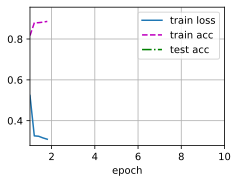

In [ ]:
# ===== 超参数设置 =====
lr, num_epochs, batch_size = 0.1, 10, 256
# lr         = 0.1   学习率（DenseNet 全程 BatchNorm，训练稳定，可用较大 lr）
# num_epochs = 10    训练轮数
# batch_size = 256   较大批量（稳定 BN 统计量 + 充分利用 GPU）

# ===== 加载 Fashion-MNIST 数据集 =====
# resize=96：28×28 放大到 96×96
#   DenseNet 计算量较大，96 比 224 快很多；
#   末尾 AdaptiveAvgPool2d(1,1) 解耦输入尺寸，96 输入完全可行
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size, resize=96)

# ===== 开始训练 =====
# d2l.train_ch6：训练主循环（前向 → 损失 → 反向 → 更新 → 每轮测试评估）
# d2l.try_gpu()：优先 GPU，无则回退 CPU
d2l.train_ch6(net, train_iter, test_iter, num_epochs, lr, d2l.try_gpu())

## 小结

* 在跨层连接上，不同于ResNet中将输入与输出相加，稠密连接网络（DenseNet）在通道维上连结输入与输出。
* DenseNet的主要构建模块是稠密块和过渡层。
* 在构建DenseNet时，我们需要通过添加过渡层来控制网络的维数，从而再次减少通道的数量。
